In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order

In [ ]:
pd.crosstab(df["category"], df["isBestSeller"])

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [6]:
pd.crosstab(df["category"], df["isBestSeller"], normalize="index")
best = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")

best.sort_values(True, ascending=False)


isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


The crosstab analysis shows that some product categories have a higher proportion of best-seller items than others. This indicates that bestseller status is more prevalent in specific categories, possibly due to stronger consumer demand or market concentration.

In [9]:
# Chi-Square Test
from scipy.stats import chi2_contingency

table = pd.crosstab(df["category"], df["isBestSeller"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


In [10]:
# Cramer's V
n = table.sum().sum()
min_dim = min(table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramer's V:", cramers_v)

Cramer's V: 0.1222829439760564


<Axes: xlabel='category'>

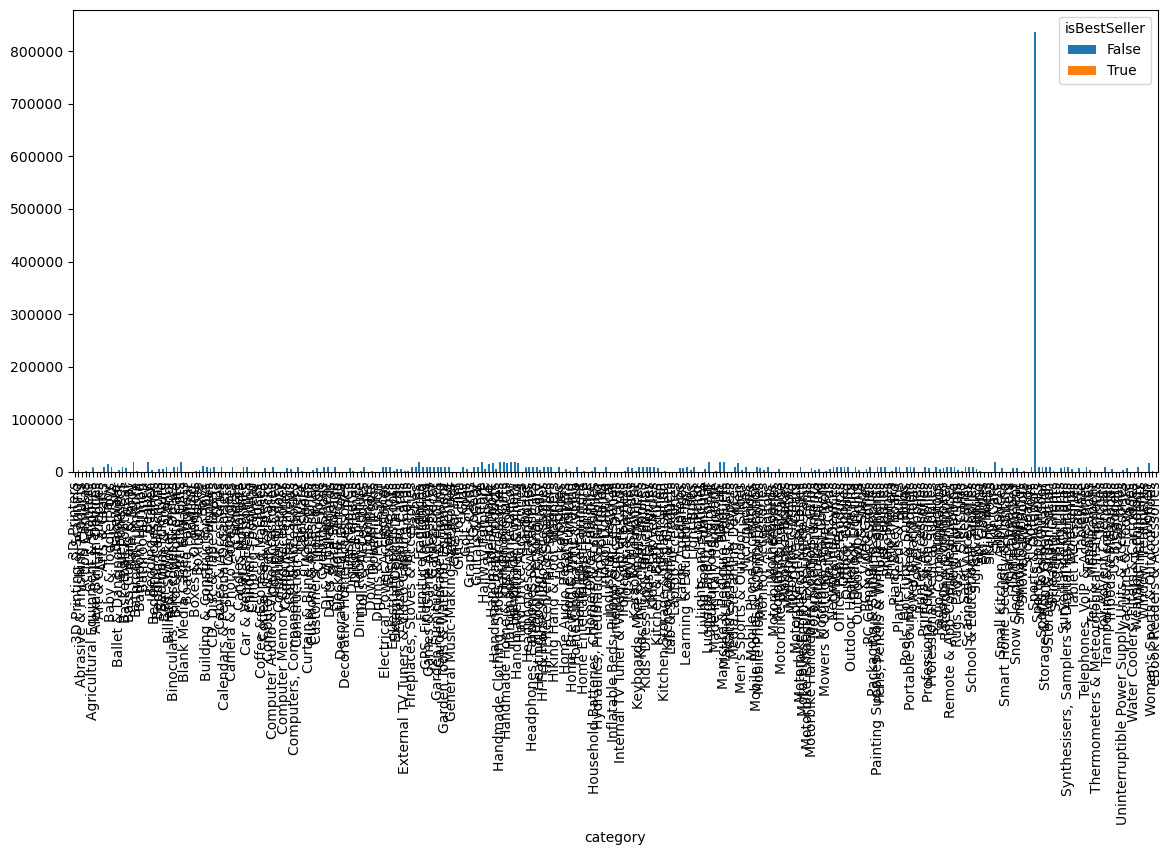

In [11]:
# Visualization
pd.crosstab(df["category"], df["isBestSeller"]).plot(kind="bar", stacked=True, figsize=(14,6))

Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.
Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.
Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [ ]:
# Remove outliers

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_clean = df[(df["price"] >= lower) & (df["price"] <= upper)]

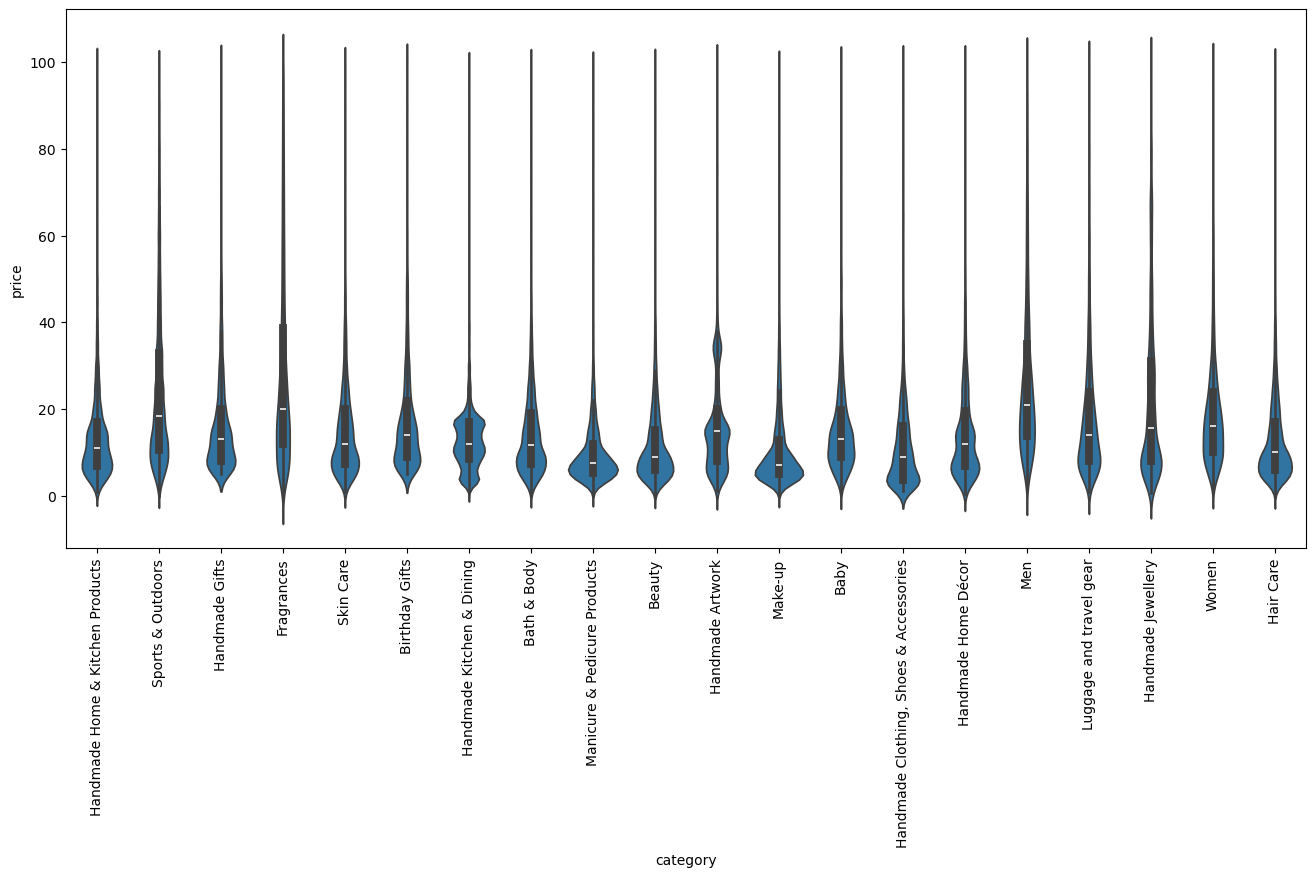

In [13]:
top20 = df_clean["category"].value_counts().head(20).index

plt.figure(figsize=(16,7))
sns.violinplot(
    data=df_clean[df_clean["category"].isin(top20)],
    x="category",
    y="price"
)

plt.xticks(rotation=90)
plt.show()

In [14]:
# Which categorie tends to have the highest median price?
df_clean.groupby("category")["price"].median().sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

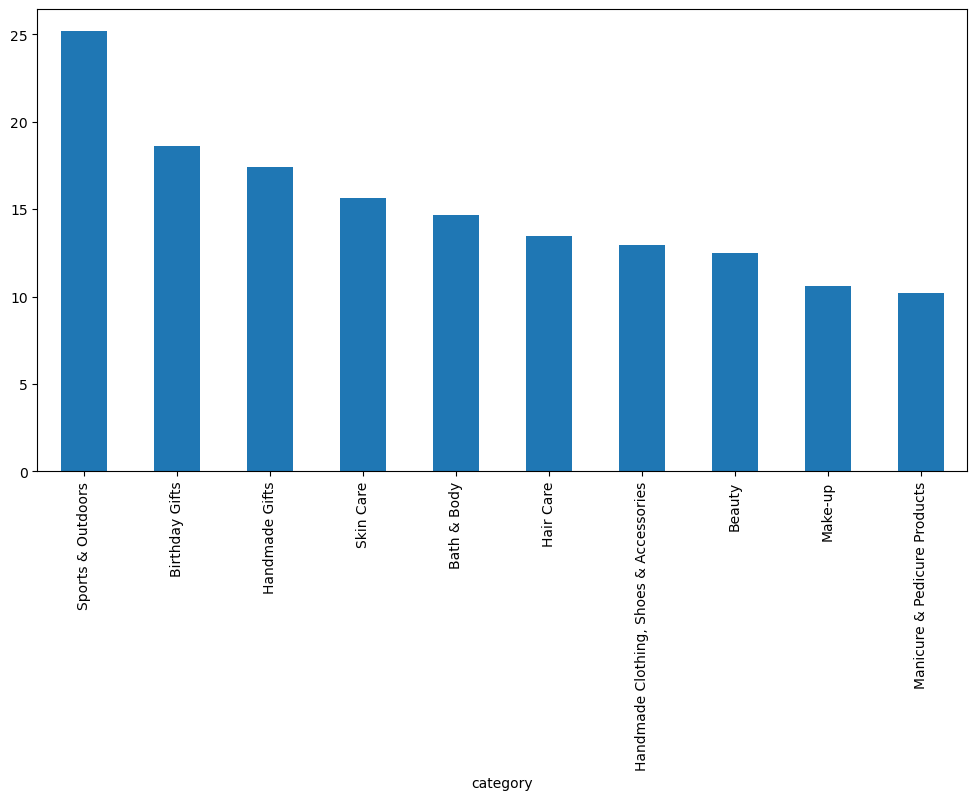

In [15]:
top10 = df_clean["category"].value_counts().head(10).index

avg_price = (
    df_clean[df_clean["category"].isin(top10)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

avg_price.plot(kind="bar", figsize=(12,6))
plt.show()

In [16]:
df_clean.groupby("category")["price"].mean().sort_values(ascending=False).head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

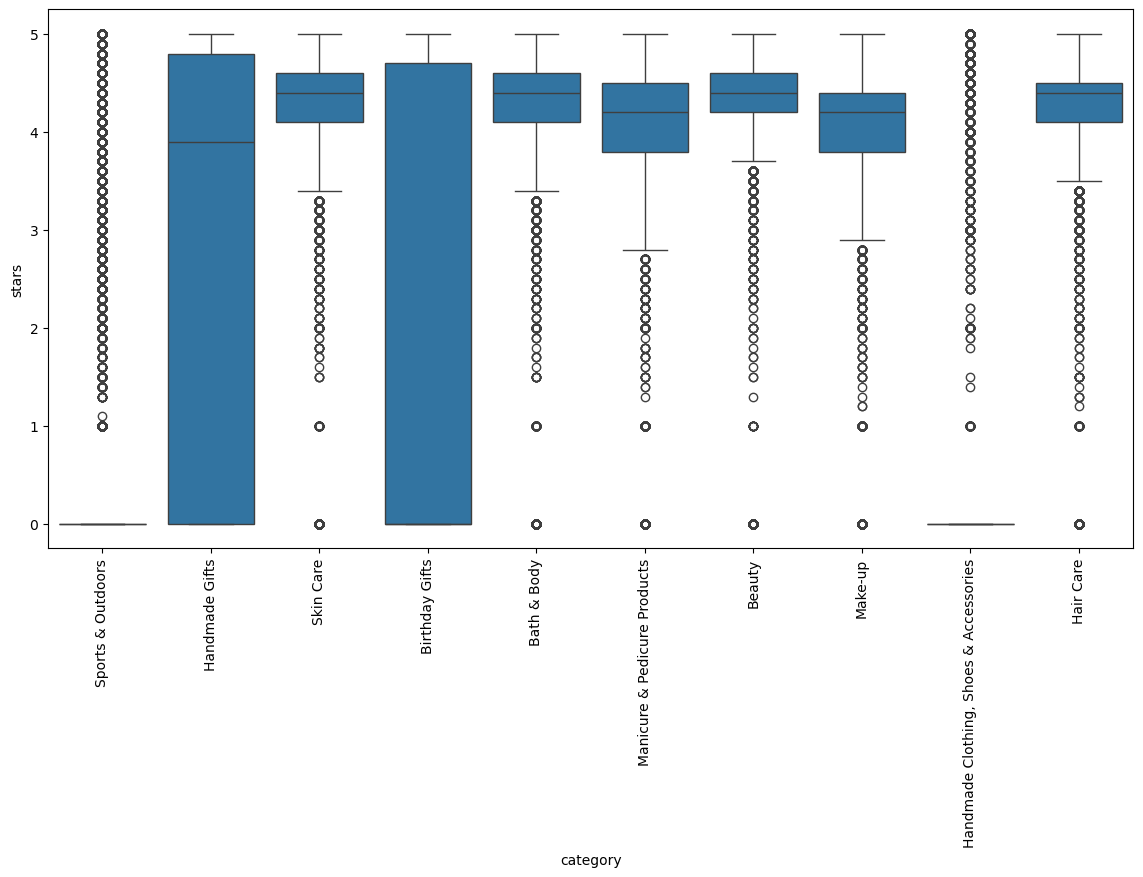

In [17]:
top10 = df_clean["category"].value_counts().head(10).index

plt.figure(figsize=(14,7))
sns.boxplot(
    data=df_clean[df_clean["category"].isin(top10)],
    x="category",
    y="stars"
)

plt.xticks(rotation=90)
plt.show()

In [18]:
df_clean.groupby("category")["stars"].median().sort_values(ascending=False).head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [19]:
df_clean[["price", "stars"]].corr()

,price,stars
price,1.000000,-0.077673
stars,-0.077673,1.000000


The correlation between price and stars is -0.078, indicating a very weak negative relationship. This suggests that more expensive products do not necessarily receive better customer ratings. Product ratings are likely influenced by other factors beyond price.

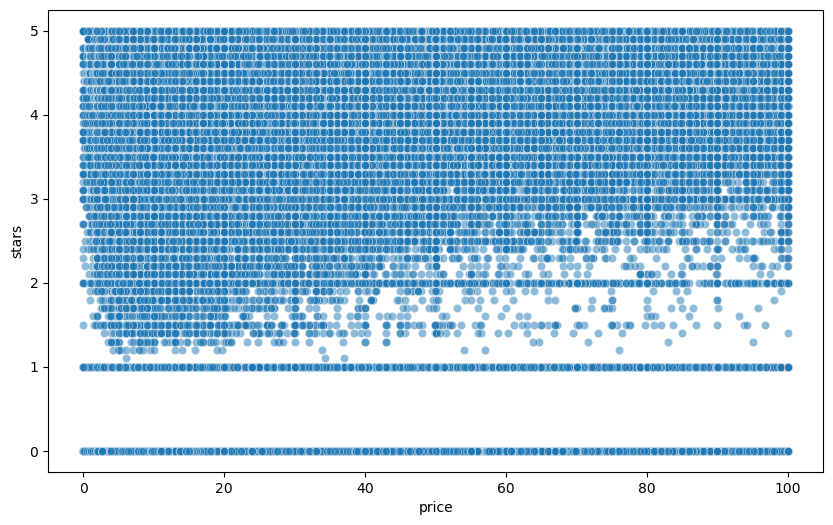

In [20]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_clean, x="price", y="stars", alpha=0.5)
plt.show()

The scatter plot shows no clear linear relationship between price and customer ratings. Ratings are widely distributed across all price levels, confirming the weak correlation found previously. Most products cluster between 3 and 5 stars, indicating generally positive customer feedback regardless of price.

plt.figure(figsize=(8,6))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

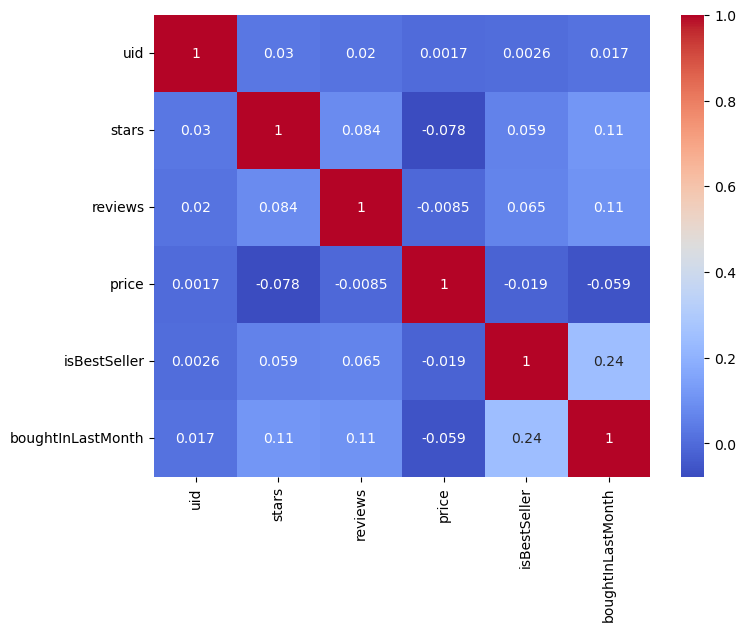

In [21]:
plt.figure(figsize=(8,6))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

The heatmap shows generally weak correlations among numerical variables. Price has a very weak negative correlation with stars (-0.078), indicating that expensive products do not necessarily receive better ratings. The strongest relationship is between bestseller status and purchases in the last month (0.24), suggesting that bestseller products tend to generate more recent sales activity.

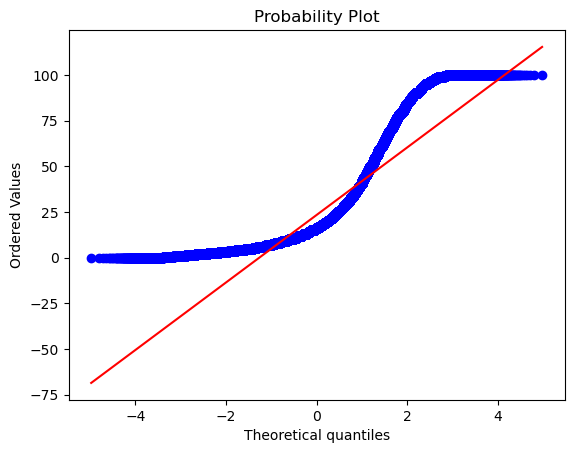

In [22]:
import scipy.stats as stats

stats.probplot(df_clean["price"], dist="norm", plot=plt)
plt.show()

The QQ plot shows a clear deviation from the reference line, indicating that product prices are not normally distributed. Prices appear skewed and concentrated within specific ranges, which is common in e-commerce datasets where many products are low to mid-priced and fewer products are premium-priced.